# single-load

In [1]:
%load_ext autoreload
%autoreload 2

%pip install -r requirements.txt
%pip install -e .
%pip install matplotlib

import selfmade.nb101 as nb101
import selfmade.nbcore as nbcore

records = r'.\datas\nasbench_full.tfrecord'
space = nb101.NASBench101Space()
evaluator = nb101.NASBench101Evaluator(records, space)

Note: you may need to restart the kernel to use updated packages.
Obtaining file:///F:/vinh/vscs/fi
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Attempting uninstall: nasbench
    Found existing installation: nasbench 1.0
    Uninstalling nasbench-1.0:
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 2] The system cannot find the file specified: 'f:\\vinh\\vscs\\fi\\venv37\\lib\\site-packages\\nasbench.egg-link'



Note: you may need to restart the kernel to use updated packages.



Loading dataset from file... This may take a few minutes...
Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
Loaded dataset in 116 seconds


In [2]:
from sklearn.ensemble import RandomForestRegressor
import secrets
import matplotlib.pyplot as plt
import pandas as pd

# main functions

In [3]:
# Full vanilla (100 evals -> 10 pop, 10 iters)
def vanilla_run(loops, pop):
    pop.evolve_loop(total_gen=loops)
    return pop

In [4]:
# Half vanilla, half guided (100 evals -> 10 pop, 5 val, 5 gui)
def guided_run(loops, pop):
    split = int(loops/2)
    print("Half vanilla")
    pop.evolve_loop(total_gen=split)

    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    imp = fi.pipeline(pop.data, rf)

    gui = nbcore.Guidance(space, imp, pop.config)
    gui.sortNsplit()
    gui.calculate_guidance()

    print("Half guided")
    pop.evolve_loop(total_gen=split, guidance = gui)
    return pop

In [5]:
def compare_run(pop : nbcore.Population, loops = 20):
    split = int(loops / 2)
    print("Common half")
    pop.evolve_loop(total_gen = split)
    
    fv_pop = pop.copy()
    sv_pop = pop.copy()
    
    print("Full vanilla")
    fv_pop.evolve_loop(total_gen = split)
    
    print("Half guided")
    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    for _ in range(split):
        imp = fi.pipeline(sv_pop.data, rf)

        gui = nbcore.Guidance(space, imp, sv_pop.config)
        gui.sortNsplit()
        gui.calculate_guidance()
        sv_pop.guidance = gui
        sv_pop.evolve()
    
    return fv_pop, sv_pop

# test run

In [6]:
pop_size = 100
total_gen = 20
# Set seed và population chung để tạo tính công bằng cho 2 lượt chạy khác nhau
nb101.set_seed(42)
share_pop = nbcore.Population(pop_size, space, evaluator)
share_pop.initialize()
vanilla = share_pop.copy()
guided = share_pop.copy()

Best performance: 0.9458132982254028
Recording generation 0
Finished recording


In [7]:
# fv = guided_run(total_gen, vanilla)
# sv = vanilla_run(total_gen, guided)

fv, sv = compare_run(share_pop)

Common half
Generation 1 - Best performance: 0.9458132982254028
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9471153616905212
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9474158883094788
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9474158883094788
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9474158883094788
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9474158883094788
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9485176205635071
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9490184187889099
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9490184187889099
Recording generation 9
Finished recording
Generation 10 - Best performance: 0.9490184187889099
Recording generation 10
Finished recording
Full vanilla
Generation 11 - Best performance:

# plot on vanilla + guided and compare with full vanilla

In [8]:
int_ticks = range(0, total_gen + 1, 2)

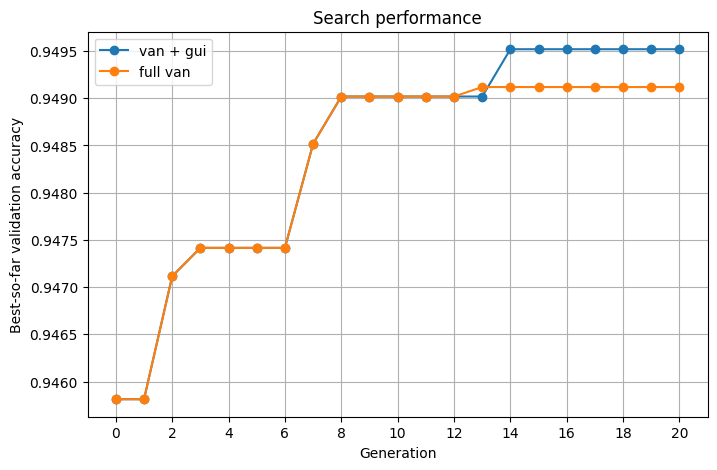

In [9]:
hist = pd.DataFrame(sv.best_history)
hist2 = pd.DataFrame(fv.best_history)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["best_so_far"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["best_so_far"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Search performance")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

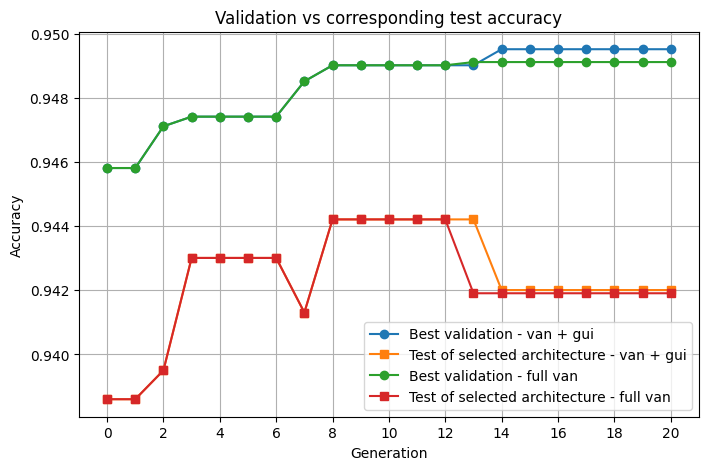

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    hist["generation"],
    hist["best_val"],
    marker="o",
    label="Best validation - van + gui"
)

plt.plot(
    hist["generation"],
    hist["best_test"],
    marker="s",
    label="Test of selected architecture - van + gui"
)

plt.plot(
    hist2["generation"],
    hist2["best_val"],
    marker="o",
    label="Best validation - full van"
)

plt.plot(
    hist2["generation"],
    hist2["best_test"],
    marker="s",
    label="Test of selected architecture - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Accuracy")
plt.title("Validation vs corresponding test accuracy")
plt.legend()
plt.grid(True)
plt.show()

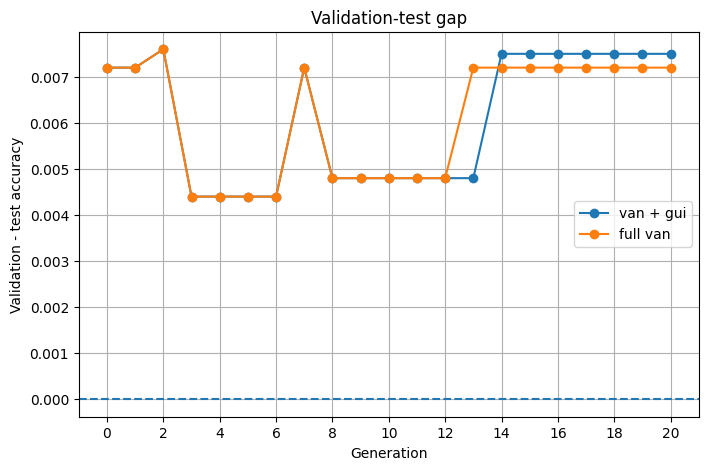

In [11]:
hist["val_test_gap"] = (
    hist["best_val"] - hist["best_test"]
)

hist2["val_test_gap"] = (
    hist2["best_val"] - hist2["best_test"]
)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["val_test_gap"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["val_test_gap"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation - test accuracy")
plt.title("Validation-test gap")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

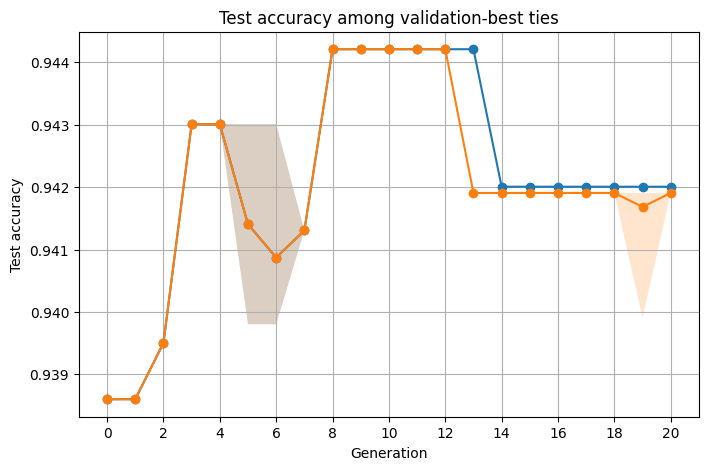

In [12]:
plt.figure(figsize=(8, 5))

x = hist["generation"]
x2 = hist2["generation"]

plt.plot(
    x,
    hist["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - van + gui"
)

plt.fill_between(
    x,
    hist["tied_test_min"],
    hist["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - van + gui"
)

plt.plot(
    x2,
    hist2["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - full van"
)

plt.fill_between(
    x2,
    hist2["tied_test_min"],
    hist2["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Test accuracy")
plt.title("Test accuracy among validation-best ties")
# plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

In [13]:
df = pd.DataFrame(sv.data)
df2 = pd.DataFrame(fv.data)

population_stats = (
    df.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

population_stats2 = (
    df2.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

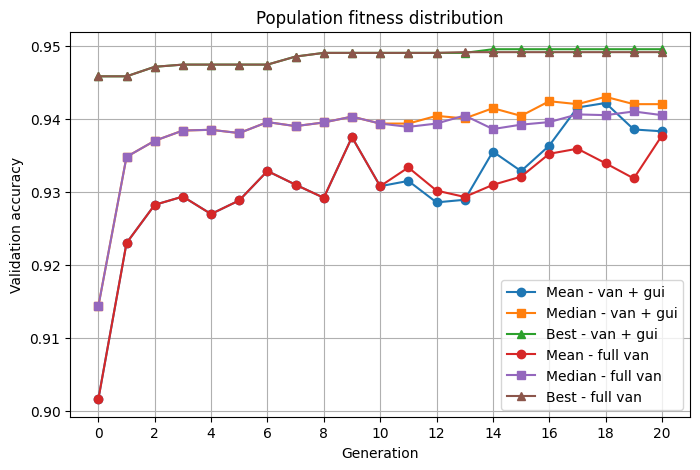

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    population_stats["generation"],
    population_stats["mean"],
    marker="o",
    label="Mean - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["median"],
    marker="s",
    label="Median - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["max"],
    marker="^",
    label="Best - van + gui"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["mean"],
    marker="o",
    label="Mean - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["median"],
    marker="s",
    label="Median - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["max"],
    marker="^",
    label="Best - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation accuracy")
plt.title("Population fitness distribution")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
def genome_signature(rep):
    return (
        rep["code"],
        tuple(rep["operations"])
    )

In [16]:
df["signature"] = df["representation"].apply(genome_signature)
df2["signature"] = df2["representation"].apply(genome_signature)

diversity = (
    df.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

diversity2 = (
    df2.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

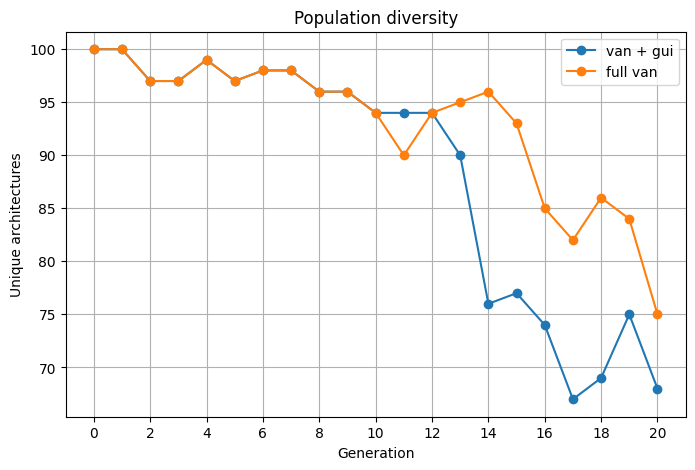

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    diversity["generation"],
    diversity["unique_architectures"],
    marker="o"
)

plt.plot(
    diversity2["generation"],
    diversity2["unique_architectures"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Unique architectures")
plt.title("Population diversity")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

# seed loop

In [18]:
def loopy_loop(n_runs, size, loops):
    fv_seed = []
    sv_seed = []
    seeds = []

    for run in range(n_runs):
        s = secrets.randbits(32)
        seeds.append(s)

        print(f"Running {run + 1}/{n_runs} | seed = {s}")

        nb101.set_seed(s)
        com_pop = nbcore.Population(size, space, evaluator)
        com_pop.initialize()
        # van = com_pop.copy()
        # gui = com_pop.copy()

        # fv = vanilla_run(loops, van)
        # sv = guided_run(loops, gui)

        fv, sv = compare_run(com_pop, loops=loops)
        
        fv_seed.append(fv)
        sv_seed.append(sv)

    return fv_seed, sv_seed, seeds

In [19]:
runs = 50
pop = 100
evo = 30
fv, sv, seeds = loopy_loop(runs, pop, evo)
# fv, sv, seeds = loopy_loop(20, pop_size * 2, 50)

Running 1/50 | seed = 2206732566
Best performance: 0.9428085088729858
Recording generation 0
Finished recording
Common half
Generation 1 - Best performance: 0.9471153616905212
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9471153616905212
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9481169581413269
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9485176205635071
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9485176205635071
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9485176205635071
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9485176205635071
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9485176205635071
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9485176205635071
Recording generation 9
Finished recording
Generation 10 - Best performan

In [20]:
def make_history_df(runs, seeds, method):
    rows = []

    for pop, seed in zip(runs, seeds):
        for h in pop.best_history:
            rows.append({
                "seed": seed,
                "method": method,
                "generation": h["generation"],
                "best_val": h["best_val"],
                "best_so_far": h["best_so_far"],
                "best_test": h["best_test"],
                "tied_test_min": h["tied_test_min"],
                "tied_test_max": h["tied_test_max"],
                "tied_test_mean": h["tied_test_mean"],
                "num_tied": h["num_tied"],
            })

    return pd.DataFrame(rows)

In [21]:
vanilla_df = make_history_df(fv,seeds,"Vanilla")
guided_df = make_history_df(sv,seeds,"Guided")

history_df = pd.concat([vanilla_df, guided_df],ignore_index=True)

In [22]:
import numpy as np

def summarize(df):
    summary = (
        df.groupby(["method", "generation"])["best_so_far"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    summary["sem"] = (
        summary["std"] /
        np.sqrt(summary["count"])
    )

    summary["ci95"] = 1.96 * summary["sem"]

    return summary

In [23]:
ticks = range(0, evo + 1, 2)

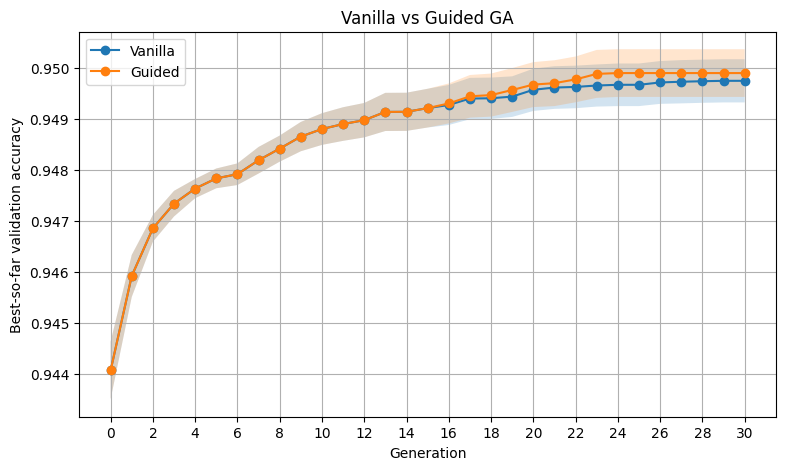

In [24]:
summary = summarize(history_df)

plt.figure(figsize=(9, 5))

for method in ["Vanilla", "Guided"]:
    d = summary[summary["method"] == method]

    plt.plot(
        d["generation"],
        d["mean"],
        marker="o",
        label=method
    )

    plt.fill_between(
        d["generation"],
        d["mean"] - d["ci95"],
        d["mean"] + d["ci95"],
        alpha=0.2
    )

plt.xticks(ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Vanilla vs Guided GA")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
def final_results(df):
    final = (
        df.sort_values("generation")
        .groupby(["seed", "method"])
        .tail(1)
    )

    return final

In [26]:
final = final_results(history_df)

pivot = final.pivot(
    index="seed",
    columns="method",
    values="best_so_far"
)

pivot["improvement"] = (
    pivot["Guided"] - pivot["Vanilla"]
)

print(pivot)

method        Guided   Vanilla  improvement
seed                                       
336470912   0.948117  0.948117     0.000000
502814833   0.949519  0.949519     0.000000
529170915   0.951823  0.951823     0.000000
607603875   0.948918  0.948918     0.000000
949948278   0.948518  0.948518     0.000000
1022236360  0.951823  0.949519     0.002304
1094996777  0.951823  0.951823     0.000000
1182307286  0.947216  0.947216     0.000000
1194996196  0.951823  0.951823     0.000000
1281856077  0.951823  0.951823     0.000000
1288490044  0.951823  0.949519     0.002304
1307253905  0.951823  0.951823     0.000000
1338735997  0.947216  0.947216     0.000000
1444943593  0.949519  0.949519     0.000000
1449095309  0.951823  0.951823     0.000000
1484257974  0.948718  0.949519    -0.000801
1535164222  0.949519  0.949519     0.000000
1579499698  0.949018  0.949018     0.000000
1728927810  0.951823  0.951823     0.000000
1784807897  0.948918  0.949519    -0.000601
2015700791  0.948117  0.949519  

In [27]:
import numpy as np
from scipy.stats import wilcoxon

# Compare test accuracy of the selected architecture
test_pivot = final.pivot(
    index="seed",
    columns="method",
    values="best_test"
).dropna()

diff = test_pivot["Guided"] - test_pivot["Vanilla"]

print("Mean test accuracy:")
print(test_pivot[["Vanilla", "Guided"]].mean())

print("\nPaired test-accuracy differences (Guided - Vanilla):")
print("Mean:", diff.mean())
print("Median:", diff.median())
print("Wins:", (diff > 0).sum())
print("Ties:", (diff == 0).sum())
print("Losses:", (diff < 0).sum())

non_ties = diff[diff != 0]
if len(non_ties) > 0:
    print(
        "Wilcoxon p-value:",
        wilcoxon(non_ties).pvalue
    )

# Bootstrap confidence interval for the mean paired difference
rng = np.random.default_rng(42)
d = diff.to_numpy()
boot_means = np.array([
    rng.choice(d, size=len(d), replace=True).mean()
    for _ in range(20000)
])

print(
    "95% bootstrap CI:",
    np.quantile(boot_means, [0.025, 0.975])
)


Mean test accuracy:
method
Vanilla    0.942117
Guided     0.942322
dtype: float64

Paired test-accuracy differences (Guided - Vanilla):
Mean: 0.0002043306827545166
Median: 0.0
Wins: 8
Ties: 37
Losses: 5
Wilcoxon p-value: 0.127197265625
95% bootstrap CI: [-2.40349770e-05  4.74762917e-04]


In [28]:
pivot["good"] = (pivot["improvement"] >= 0).astype(int)
pivot["good"].value_counts()

1    43
0     7
Name: good, dtype: int64

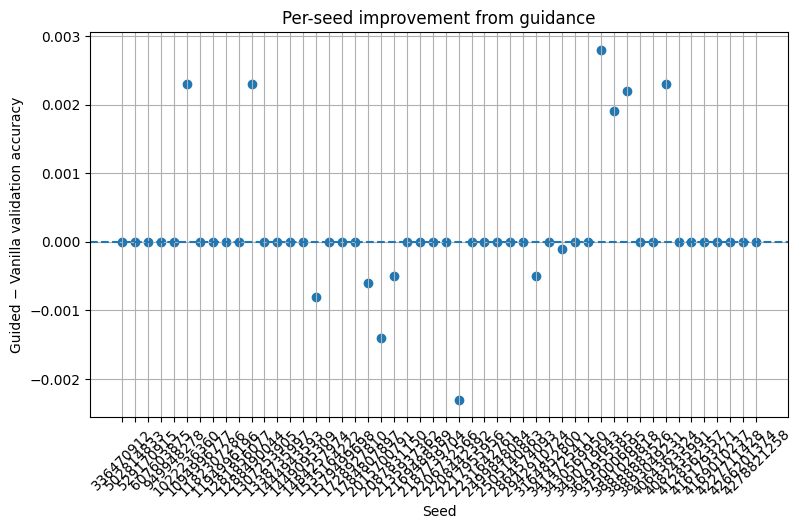

In [29]:
plt.figure(figsize=(9, 5))

x = np.arange(len(pivot))

plt.axhline(
    0,
    linestyle="--"
)

plt.scatter(
    x,
    pivot["improvement"]
)

plt.xticks(
    x,
    [str(s) for s in pivot.index],
    rotation=45
)

plt.xlabel("Seed")
plt.ylabel("Guided − Vanilla validation accuracy")
plt.title("Per-seed improvement from guidance")
plt.grid(True)
plt.show()

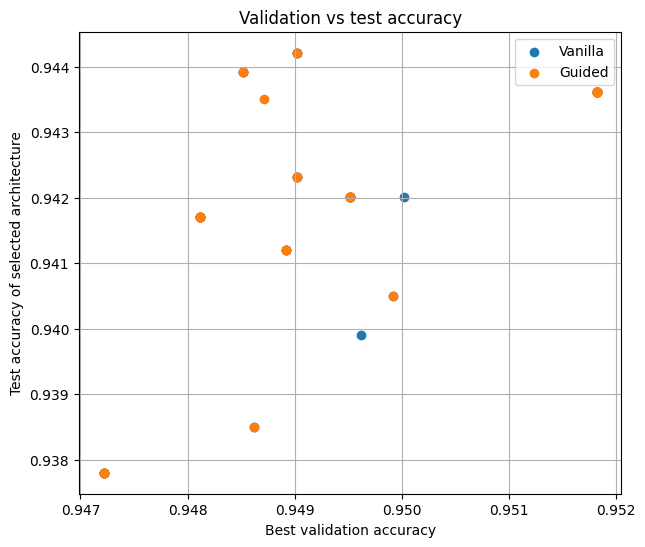

In [30]:
final_val = final.copy()

plt.figure(figsize=(7, 6))

for method in ["Vanilla", "Guided"]:
    d = final_val[final_val["method"] == method]

    plt.scatter(
        d["best_so_far"],
        d["best_test"],
        label=method
    )

plt.xlabel("Best validation accuracy")
plt.ylabel("Test accuracy of selected architecture")
plt.title("Validation vs test accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
final_val["val_test_gap"] = (
    final_val["best_so_far"]
    - final_val["best_test"]
)

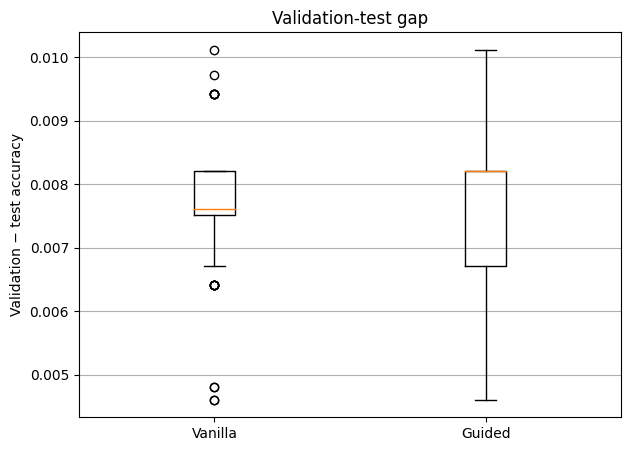

In [32]:
plt.figure(figsize=(7, 5))

groups = [
    final_val[
        final_val["method"] == "Vanilla"
    ]["val_test_gap"],

    final_val[
        final_val["method"] == "Guided"
    ]["val_test_gap"]
]

plt.boxplot(
    groups,
    labels=["Vanilla", "Guided"]
)

plt.ylabel("Validation − test accuracy")
plt.title("Validation-test gap")
plt.grid(True, axis="y")
plt.show()